# Tension composition — stochastic line tension on top of directional and adhesion tension

This notebook accompanies `tension_composition.py`. It shows two tension processes driving the
**same junctions at the same time**:

| scenario | deterministic process | + noise | parent experiment |
|---|---|---|---|
| **ce** (convergent extension) | `DirectionalLineTension` (polarity along $x$, $\Lambda$ from 0 to 0.15, $\cos^2$ law) | `StochasticLineTension` | `Experiments/directional_tension` |
| **sort** (cell sorting) | `DifferentialAdhesion` ($\Lambda_\mathrm{homo} = 0.05$, $\Lambda_\mathrm{het} = 0.45$) | `StochasticLineTension` | `Experiments/differential_adhesion` |

**How two processes share one parameter.** Each parameter-setting process ships a *delta*, not a
new value. It moves only its own **share** of `line_tension`, and it mirrors that share in its
own `edge_df` column. The `update_parameter` behavior adds the delta in place. So

$$
\texttt{line\_tension} \;=\; \underbrace{\texttt{directional\_tension}}_{\Lambda(\theta)}
\;+\; \underbrace{\texttt{stochastic\_tension}}_{x_{ij}(t)}
\qquad\text{or}\qquad
\texttt{line\_tension} \;=\; \underbrace{\texttt{adhesion\_tension}}_{\Lambda_\mathrm{homo}\ \text{or}\ \Lambda_\mathrm{het}}
\;+\; x_{ij}(t),
$$

where each junction's stochastic share $x_{ij}$ is an Ornstein–Uhlenbeck process that relaxes to 0:

$$
x_{ij}(t+\Delta t) = e^{-\Delta t/\tau}\,x_{ij}(t) + \sigma\sqrt{1-e^{-2\Delta t/\tau}}\;\xi_{ij},
\qquad \xi_{ij}\sim\mathcal N(0,1).
$$

Before this change a tension process overwrote `line_tension`. Running two of them at once kept
whichever ran last in each step, so these combinations could not be simulated.

**Runs.** For each scenario: no noise (the parent's main run), noise of amplitude
$\sigma \in \{0.025, 0.05, 0.1\}$ on top (persistence $\tau = 1$), and a noise-only control at
$\sigma = 0.1$. For **ce** the control has no directional tension. For **sort** the control has
uniform $\Lambda_\mathrm{homo}$, which is the parent's control.

Run `python tension_composition.py` first. This notebook only reads `outputs/`.

In [1]:
from __future__ import annotations

import json
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.collections import LineCollection, PolyCollection
from IPython.display import Image, display

import tension_composition as tc     # the run script is the single source of truth
sys.path.insert(0, str(tc.REPO / "Experiments"))

OUT_DIR = tc.OUT_DIR
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIG_DPI = 300
GIF_DPI = 110
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

RUNS = {s: tc.runs(s) for s in ("ce", "sort")}
MESH = {s: json.loads((OUT_DIR / f"mesh_{s}.json").read_text()) for s in ("ce", "sort")}
METRICS = {s: pd.read_csv(OUT_DIR / f"metrics_{s}.csv") for s in ("ce", "sort")}
SUMMARY = {s: pd.DataFrame(json.loads((OUT_DIR / f"runs_{s}.json").read_text())) for s in ("ce", "sort")}

# no noise in black, the noise levels in a sequential blue ramp, the noise-only control in grey
def run_colors(scenario):
    names = list(RUNS[scenario])
    blues = plt.cm.Blues(np.linspace(0.45, 0.95, len(tc.SIGMAS)))
    out = {"none": "#000000", names[-1]: "#999999"}
    out.update({f"s{s:g}": blues[i] for i, s in enumerate(tc.SIGMAS)})
    return out

COLORS = {s: run_colors(s) for s in RUNS}
CELL_TYPE_COLORS = {"A": "#0072B2", "B": "#E69F00"}
print("tau =", tc.TAU, " sigmas =", tc.SIGMAS)

tau = 1.0  sigmas = [0.025, 0.05, 0.1]


## 1. The composites

Each scenario is its parent's composite with a `Stochastic` process added. Both regulators read
`Tissue State` and push `update_parameter` (or `differential_adhesion`) behaviors into the same
`Behaviors` store, and the `EulerSolver` applies all of them. Shown here for $\sigma = 0.05$.

In [2]:
from bigraph_style import plot_experiment_bigraph
from vivarium_tyssue.core import build_core

core = build_core()
for scenario, spec_fn in (("ce", tc.ce_spec), ("sort", tc.sort_spec)):
    display(plot_experiment_bigraph(
        spec_fn(RUNS[scenario]["s0.05"], MESH[scenario]), core=core,
        filename=f"{scenario}_bigraph", out_dir=OUT_DIR / "bigraphs"))

wrote /Users/tasnifrahman/PycharmProjects/vivarium-tyssue/Experiments/tension_composition/outputs/bigraphs/ce_bigraph.png


wrote /Users/tasnifrahman/PycharmProjects/vivarium-tyssue/Experiments/tension_composition/outputs/bigraphs/sort_bigraph.png


## 2. The runs

`max_residual` is $\max |\texttt{line\_tension} - \text{share} - \texttt{stochastic\_tension}|$
over every junction of every recorded frame. It is 0 up to floating-point rounding, so the two
shares always add up to exactly the tension the mechanics sees. `final_valid` is tyssue's
`Sheet.validate()` on the last mesh.

In [3]:
def final_table(scenario, keys):
    m = METRICS[scenario].groupby("run").tail(1).set_index("run")[keys]
    s = SUMMARY[scenario].set_index("run")[["sigma", "deterministic", "seconds",
                                            "final_valid", "max_residual"]]
    return s.join(m).loc[list(RUNS[scenario])]

display(final_table("ce", ["ce_index", "n_t1", "cell_elongation", "S_cell",
                           "tension_std", "negative_fraction"]).round(4))
display(final_table("sort", ["sorting_index", "heterotypic_length", "roughness",
                             "tension_std", "negative_fraction"]).round(4))

,sigma,deterministic,seconds,final_valid,max_residual,ce_index,n_t1,cell_elongation,S_cell,tension_std,negative_fraction
run,,,,,,,,,,,
none,0.000,True,71.6,True,0.0,1.9583,22,2.2525,-0.6232,0.0676,0.0000
s0.025,0.025,True,156.8,True,0.0,1.9821,223,1.7172,-0.3215,0.0661,0.1120
s0.05,0.050,True,226.9,True,0.0,2.0335,391,1.5559,-0.0994,0.0760,0.1092
s0.1,0.100,True,310.5,True,0.0,2.2837,688,1.5809,0.0961,0.1110,0.2124
noise_only_s0.1,0.100,False,288.8,True,0.0,0.9845,651,1.5041,-0.0131,0.1003,0.5288


,sigma,deterministic,seconds,final_valid,max_residual,sorting_index,heterotypic_length,roughness,tension_std,negative_fraction
run,,,,,,,,,,
none,0.000,True,90.8,True,0.0,0.5354,112.7471,0.3082,0.1995,0.0000
s0.025,0.025,True,106.4,True,0.0,0.5943,98.0397,0.2864,0.1970,0.0126
s0.05,0.050,True,127.9,True,0.0,0.6842,80.2188,0.2604,0.1917,0.1019
s0.1,0.100,True,151.4,True,0.0,0.7698,63.8935,0.2508,0.1974,0.2345
noise_only_s0.1,0.100,False,105.2,True,0.0,0.4899,197.2694,0.2052,0.0991,0.3131


## 3. The tension decomposition

The last recorded frame of the $\sigma = 0.05$ runs. **Left (ce):** each junction's
`line_tension` against its acute angle to the polarity axis. The directional share lies exactly
on $\Lambda(\theta)$, and the noise scatters the total around it. **Middle:** the stochastic
share is a centred Gaussian with standard deviation $\approx\sigma$, as an OU process at
stationarity should be. **Right (sort):** `line_tension` on homotypic and heterotypic junctions.
These are the two adhesion values, each spread by the same noise.

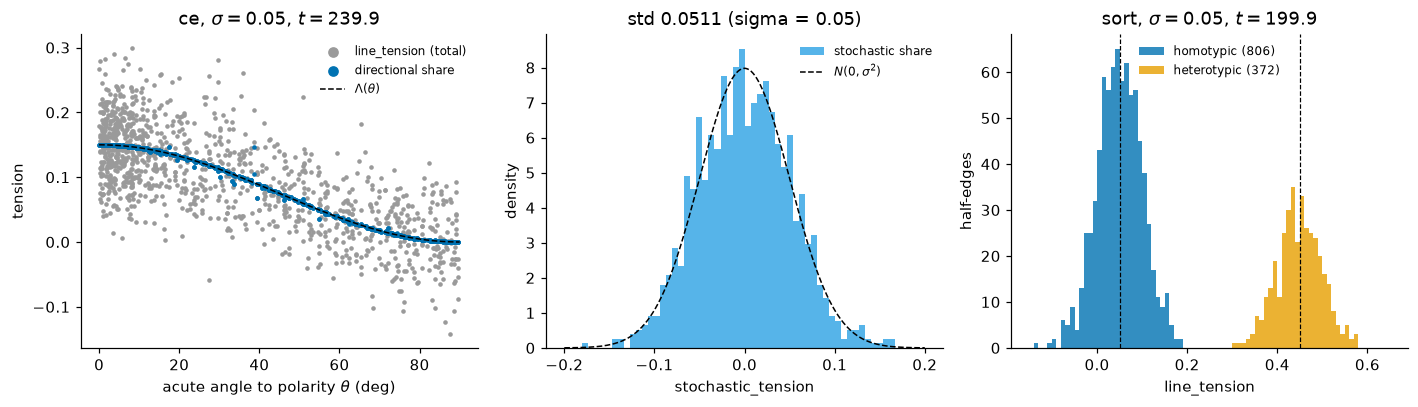

ce:   max |directional share - Lambda(theta)| = 5.48e-02 (nonzero only for junctions that moved in the last two steps)
sort: adhesion shares present: [np.float64(0.05), np.float64(0.45)]


In [4]:
def last_frame(scenario, run, key):
    with pd.HDFStore(OUT_DIR / scenario / run / "history.hf5", "r") as store:
        t = store.select_column(key, "time").max()
        return store.select(key, where=f"time == {t}"), float(t)


edge, t_ce = last_frame("ce", "s0.05", "edge")
vert, _ = last_frame("ce", "s0.05", "vert")
pos = vert.set_index("vert")[tc.CE_COORDS]
d = pos.loc[edge["trgt"]].to_numpy() - pos.loc[edge["srce"]].to_numpy()
length = np.linalg.norm(d, axis=1)
theta = np.degrees(np.arccos(np.clip(np.abs(d[:, 0]) / np.where(length > 0, length, 1), 0, 1)))

fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.8))
ax = axes[0]
ax.scatter(theta, edge["line_tension"], s=4, color="#9a9a9a", label="line_tension (total)")
ax.scatter(theta, edge["directional_tension"], s=4, color="#0072B2", label="directional share")
th = np.linspace(0, 90, 200)
ax.plot(th, tc.CE_LAMBDA_MIN + (tc.CE_LAMBDA_MAX - tc.CE_LAMBDA_MIN) * np.cos(np.radians(th)) ** 2,
        color="k", lw=1, ls="--", label=r"$\Lambda(\theta)$")
ax.set(xlabel=r"acute angle to polarity $\theta$ (deg)", ylabel="tension",
       title=rf"ce, $\sigma = 0.05$, $t = {t_ce:g}$")
ax.legend(frameon=False, fontsize=8, markerscale=3)

ax = axes[1]
x = edge["stochastic_tension"].to_numpy()
bins = np.linspace(-0.2, 0.2, 61)
ax.hist(x, bins=bins, density=True, color="#56B4E9", label="stochastic share")
g = np.linspace(-0.2, 0.2, 400)
ax.plot(g, np.exp(-g ** 2 / (2 * 0.05 ** 2)) / (0.05 * np.sqrt(2 * np.pi)), "k--", lw=1,
        label=r"$N(0, \sigma^2)$")
ax.set(xlabel="stochastic_tension", ylabel="density",
       title=f"std {x.std():.4f} (sigma = 0.05)")
ax.legend(frameon=False, fontsize=8)

edge_s, t_s = last_frame("sort", "s0.05", "edge")
ax = axes[2]
bins = np.linspace(-0.15, 0.65, 81)
for flag, label, color in ((0.0, "homotypic", "#0072B2"), (1.0, "heterotypic", "#E69F00")):
    sel = edge_s["heterotypic"] == flag
    ax.hist(edge_s.loc[sel, "line_tension"], bins=bins, alpha=0.8, color=color,
            label=f"{label} ({int(sel.sum())})")
for v in (tc.SORT_LAMBDA_HOMO, tc.SORT_LAMBDA_HET):
    ax.axvline(v, color="k", lw=0.8, ls="--")
ax.set(xlabel="line_tension", ylabel="half-edges", title=rf"sort, $\sigma = 0.05$, $t = {t_s:g}$")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "tension_decomposition.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

print("ce:   max |directional share - Lambda(theta)| =",
      f"{np.abs(edge['directional_tension'] - (tc.CE_LAMBDA_MAX * np.cos(np.radians(theta)) ** 2)).max():.2e}",
      "(nonzero only for junctions that moved in the last two steps)")
print("sort: adhesion shares present:", sorted(edge_s["adhesion_tension"].round(6).unique()))

## 4. Convergent extension under noise

$\mathrm{CE}(t) = (L_\perp/L_\parallel)\,/\,(L_\perp/L_\parallel)|_{t=0}$ is the tissue's aspect
ratio in the polarity frame, relative to its start (> 1: narrower along the polarity, longer
across it). T1s are completed neighbour exchanges: pairs of cells that become adjacent for the
first time. The metrics are those of `Experiments/directional_tension`, computed from every
recorded frame.

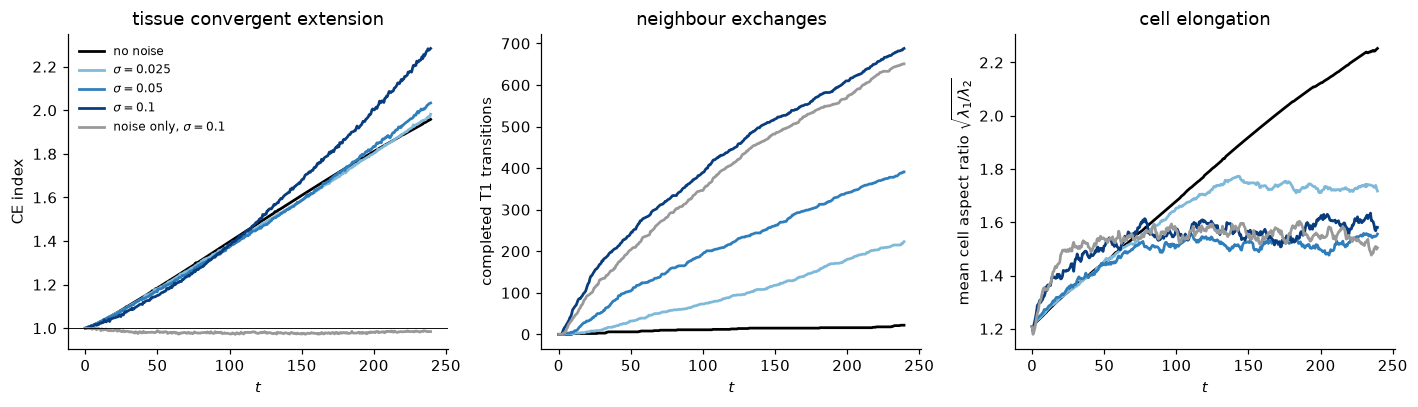

In [5]:
m = METRICS["ce"]
fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.8))
for run, spec in RUNS["ce"].items():
    r, c = m[m.run == run], COLORS["ce"][run]
    axes[0].plot(r.time, r.ce_index, color=c, lw=1.8, label=spec["label"])
    axes[1].plot(r.time, r.n_t1, color=c, lw=1.8, label=spec["label"])
    axes[2].plot(r.time, r.cell_elongation, color=c, lw=1.8, label=spec["label"])
axes[0].axhline(1, color="k", lw=0.6)
axes[0].set(xlabel="$t$", ylabel="CE index", title="tissue convergent extension")
axes[1].set(xlabel="$t$", ylabel="completed T1 transitions", title="neighbour exchanges")
axes[2].set(xlabel="$t$", ylabel=r"mean cell aspect ratio $\sqrt{\lambda_1/\lambda_2}$",
            title="cell elongation")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "ce_over_time.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### Start and end

Junctions coloured by their total `line_tension` (blue slack, red taut), on the same axes for
every panel.

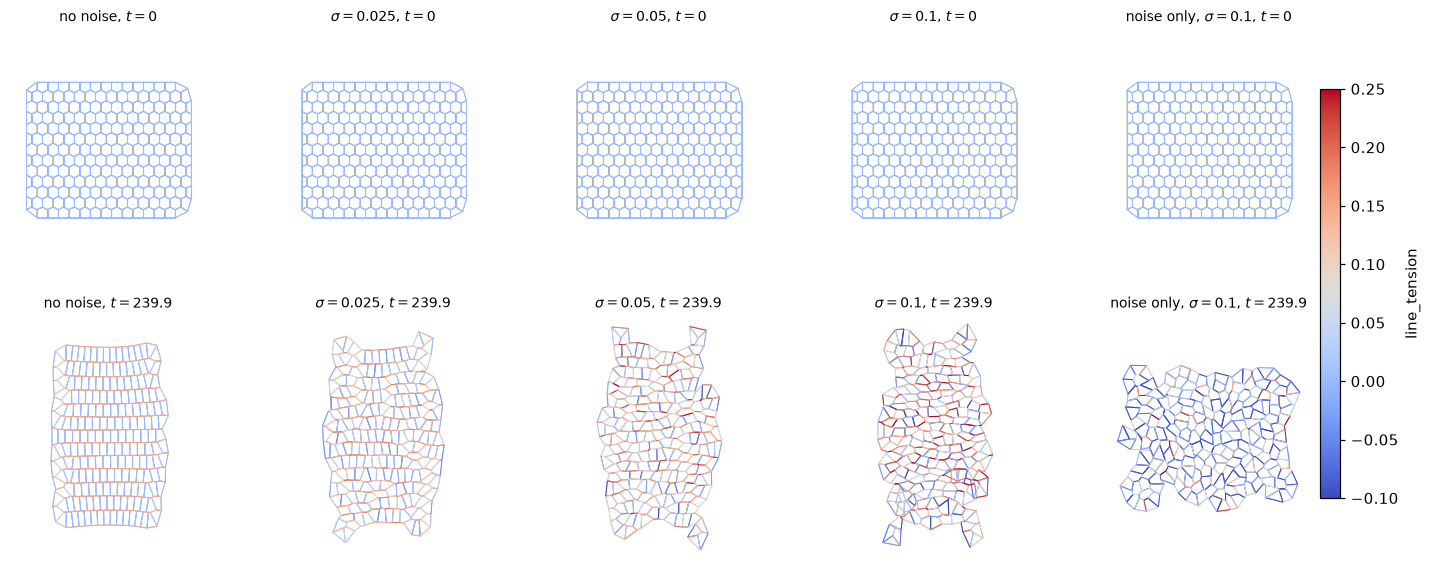

In [6]:
def ce_frame(run, t=None):
    path = OUT_DIR / "ce" / run / "history.hf5"
    with pd.HDFStore(path, "r") as store:
        times = np.sort(store.select_column("vert", "time").unique())
        t = times[-1] if t is None else times[np.argmin(np.abs(times - t))]
        v = store.select("vert", where=f"time == {t}").set_index("vert")
        e = store.select("edge", where=f"time == {t}")
    pos = np.full((int(v.index.max()) + 1, 2), np.nan)
    pos[v.index.to_numpy()] = v[tc.CE_COORDS].to_numpy(float)
    return float(t), pos, e


def face_polygons(srce, trgt, face, verts):
    order = np.argsort(face, kind="stable")
    srce, trgt, face = srce[order], trgt[order], face[order]
    starts = np.searchsorted(face, np.unique(face))
    ends = np.r_[starts[1:], len(face)]
    polys = []
    for a, b in zip(starts, ends):
        nxt = dict(zip(srce[a:b], trgt[a:b]))
        v0 = srce[a]
        ring, v = [v0], nxt.get(v0)
        while v is not None and v != v0 and len(ring) <= (b - a):
            ring.append(v)
            v = nxt.get(v)
        polys.append(verts[ring])
    return polys


TENSION_LIM = (-0.1, 0.25)

def draw_ce(ax, pos, e, xlim, ylim):
    srce, trgt = e["srce"].to_numpy(), e["trgt"].to_numpy()
    ax.add_collection(PolyCollection(face_polygons(srce, trgt, e["face"].to_numpy(), pos),
                                     facecolors="#ffffff", edgecolors="#9a9a9a",
                                     linewidths=0.4, zorder=0))
    lc = LineCollection(np.stack([pos[srce], pos[trgt]], axis=1), cmap="coolwarm",
                        linewidths=0.7, zorder=1)
    lc.set_array(e["line_tension"].to_numpy())
    lc.set_clim(*TENSION_LIM)
    ax.add_collection(lc)
    ax.set_aspect("equal"); ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    return lc


frames = {run: [ce_frame(run, 0.0), ce_frame(run)] for run in RUNS["ce"]}
allpos = np.vstack([p[~np.isnan(p).any(axis=1)] for fr in frames.values() for _, p, _ in fr])
pad = 0.6
XLIM = (allpos[:, 0].min() - pad, allpos[:, 0].max() + pad)
YLIM = (allpos[:, 1].min() - pad, allpos[:, 1].max() + pad)

runs_ce = list(RUNS["ce"])
fig, axes = plt.subplots(2, len(runs_ce), figsize=(3.2 * len(runs_ce), 6.2))
for col, run in enumerate(runs_ce):
    for row, (t, pos, e) in enumerate(frames[run]):
        lc = draw_ce(axes[row, col], pos, e, XLIM, YLIM)
        axes[row, col].set_title(f"{RUNS['ce'][run]['label']}, $t = {t:g}$", fontsize=9)
cb = fig.colorbar(lc, ax=axes, fraction=0.015, pad=0.01)
cb.set_label("line_tension")
fig.savefig(FIG_DIR / "ce_start_end.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 5. Cell sorting under noise

The sorting index $S(t) = 1 - (\text{heterotypic half-edges})/(\text{all half-edges})$ is the
fraction of junctions that separate two cells of the same type. It starts at 0.49 for the 50:50
random labelling and rises as like cells gather. The **heterotypic interface length** is what
the adhesion energy penalises. The roughness is the mean one-ring vertex deviation, the quantity
the surface smoother pulls back to its rest value. A rising roughness means the sphere's
surface is crumpling. The metrics are those of `Experiments/differential_adhesion`.

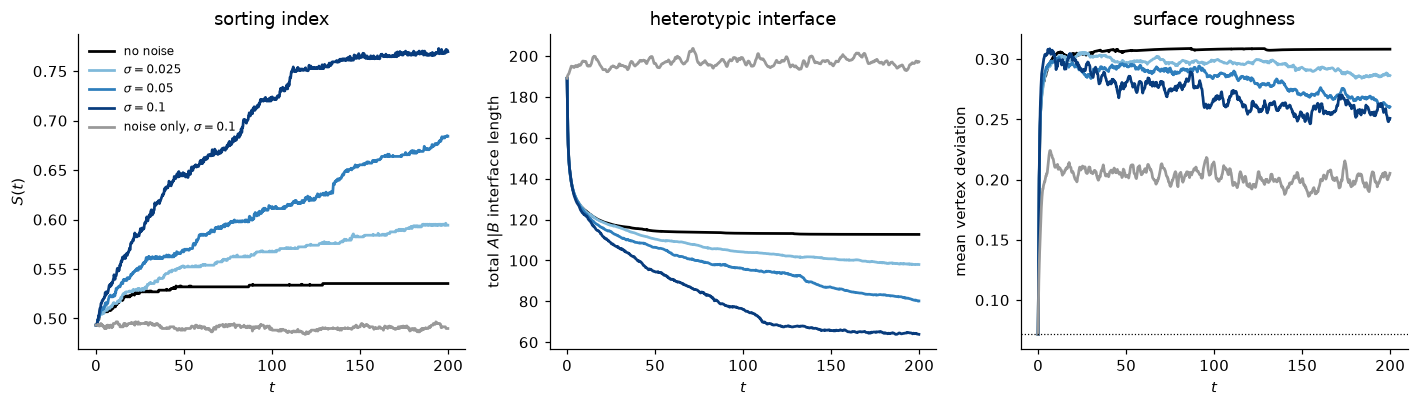

In [7]:
m = METRICS["sort"]
fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.8))
for run, spec in RUNS["sort"].items():
    r, c = m[m.run == run], COLORS["sort"][run]
    axes[0].plot(r.time, r.sorting_index, color=c, lw=1.8, label=spec["label"])
    axes[1].plot(r.time, r.heterotypic_length, color=c, lw=1.8, label=spec["label"])
    axes[2].plot(r.time, r.roughness, color=c, lw=1.8, label=spec["label"])
axes[0].set(xlabel="$t$", ylabel="$S(t)$", title="sorting index")
axes[1].set(xlabel="$t$", ylabel=r"total $A|B$ interface length", title="heterotypic interface")
axes[2].axhline(MESH["sort"]["deviation_0"], color="k", lw=0.8, ls=":")
axes[2].set(xlabel="$t$", ylabel="mean vertex deviation", title="surface roughness")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "sorting_over_time.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

### The spheres at the end

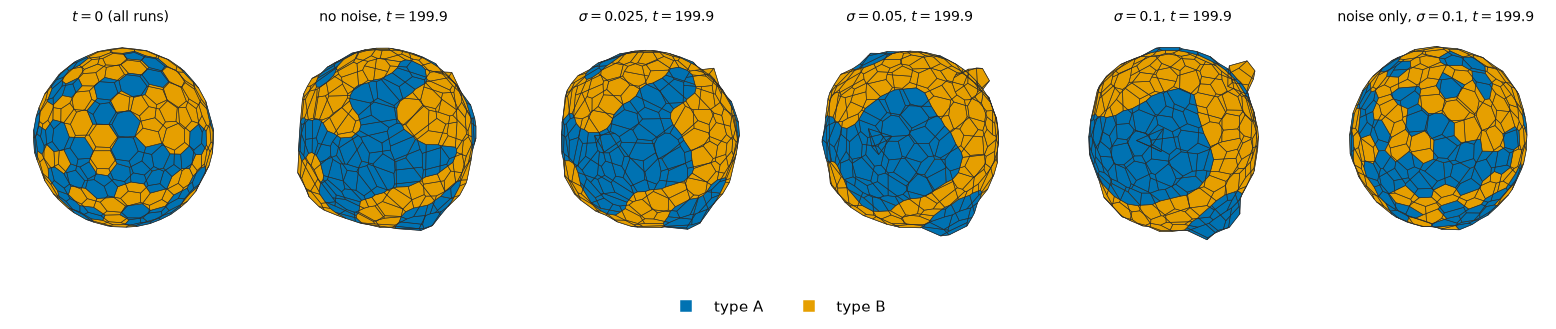

In [8]:
from tyssue import Sheet
from tyssue.draw.plt_draw import sheet_view_3d, patch_2d_collections_to_3d
from tyssue import config as tyssue_draw_config
from vivarium_tyssue.geometry import ClosedSheetVertDeviationGeometry as ClosedSheetGeometry


def sort_frame(run, t=None):
    path = OUT_DIR / "sort" / run / "history.hf5"
    with pd.HDFStore(path, "r") as store:
        times = np.sort(store.select_column("vert", "time").unique())
        t = times[-1] if t is None else times[np.argmin(np.abs(times - t))]
        dsets = {k: store.select(k, where=f"time == {t}").drop(columns="time").set_index(k)
                 for k in ("vert", "edge", "face")}
    sheet = Sheet("frame", dsets)
    ClosedSheetGeometry.update_all(sheet)
    return float(t), sheet


def draw_sphere(sheet, ax, title, half, view_angle=(22, 45)):
    specs = tyssue_draw_config.draw.sheet_spec()
    specs["face"].update(visible=True, alpha=1.0,
                         color=np.array([mcolors.to_rgba(CELL_TYPE_COLORS[t])
                                         for t in sheet.face_df["cell_type"]]))
    specs["vert"]["visible"] = False
    specs["edge"].update(visible=True, color="#2b2b2b", width=0.4)
    _, ax = sheet_view_3d(sheet, coords=tc.SORT_COORDS, ax=ax, view_angle=view_angle, **specs)
    patch_2d_collections_to_3d(ax)
    c = sheet.vert_df[tc.SORT_COORDS].to_numpy(float).mean(axis=0)
    ax.set(xlim=(c[0] - half, c[0] + half), ylim=(c[1] - half, c[1] + half),
           zlim=(c[2] - half, c[2] + half))
    ax.set_box_aspect((1, 1, 1), zoom=1.45)
    ax.set_axis_off()
    ax.set_title(title, fontsize=9)


t0, sheet0 = sort_frame("none", 0.0)
HALF = float(np.abs(sheet0.vert_df[tc.SORT_COORDS].to_numpy(float)).max()) * 1.05
runs_sort = list(RUNS["sort"])
fig = plt.figure(figsize=(3.0 * (len(runs_sort) + 1), 3.4))
ax = fig.add_subplot(1, len(runs_sort) + 1, 1, projection="3d")
draw_sphere(sheet0, ax, "$t = 0$ (all runs)", HALF)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore")
    for i, run in enumerate(runs_sort):
        t, sheet = sort_frame(run)
        ax = fig.add_subplot(1, len(runs_sort) + 1, i + 2, projection="3d")
        draw_sphere(sheet, ax, f"{RUNS['sort'][run]['label']}, $t = {t:g}$", HALF)
handles = [plt.Line2D([], [], marker="s", ls="", color=c, label=f"type {k}")
           for k, c in CELL_TYPE_COLORS.items()]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False)
fig.savefig(FIG_DIR / "sort_end.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 6. Noise level against outcome

Each scenario's end-point metric against $\sigma$. The no-noise run sits at $\sigma = 0$, and
the noise-only control is the grey marker at $\sigma = 0.1$.

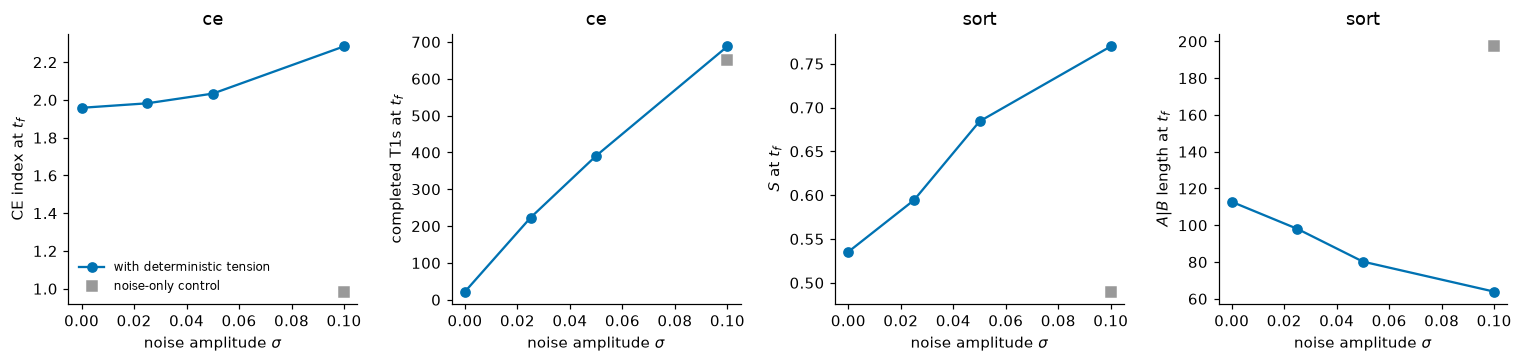

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14.0, 3.4))
panels = [("ce", "ce_index", "CE index at $t_f$"), ("ce", "n_t1", "completed T1s at $t_f$"),
          ("sort", "sorting_index", "$S$ at $t_f$"),
          ("sort", "heterotypic_length", "$A|B$ length at $t_f$")]
for ax, (scenario, key, label) in zip(axes, panels):
    last = METRICS[scenario].groupby("run").tail(1).set_index("run")
    det = [r for r, s in RUNS[scenario].items() if s["deterministic"]]
    sig = [RUNS[scenario][r]["sigma"] for r in det]
    ax.plot(sig, last.loc[det, key], "o-", color="#0072B2", label="with deterministic tension")
    ctrl = [r for r, s in RUNS[scenario].items() if not s["deterministic"]][0]
    ax.plot(RUNS[scenario][ctrl]["sigma"], last.loc[ctrl, key], "s", color="#999999",
            label="noise-only control")
    ax.set(xlabel=r"noise amplitude $\sigma$", ylabel=label, title=scenario)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "outcome_vs_sigma.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 7. Movies

One movie per scenario, at $\sigma = 0.05$, on fixed axes.

wrote /Users/tasnifrahman/PycharmProjects/vivarium-tyssue/Experiments/tension_composition/outputs/figures/ce_s0.05.gif (2.4 MB), 80 frames, dropped none


wrote /Users/tasnifrahman/PycharmProjects/vivarium-tyssue/Experiments/tension_composition/outputs/figures/sort_s0.05.gif (3.1 MB), 80 frames, dropped none


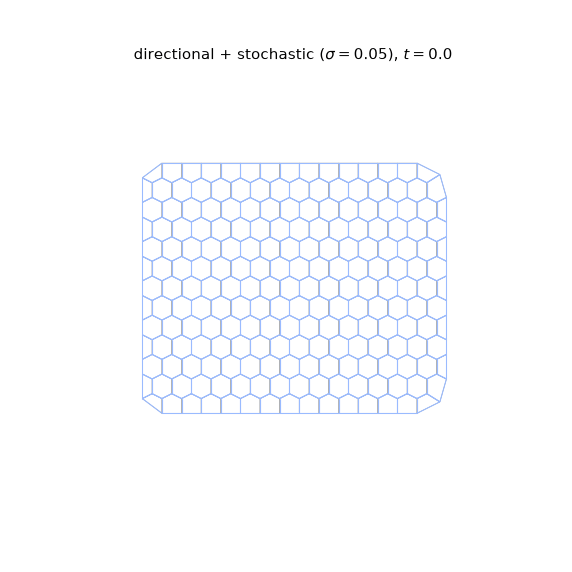

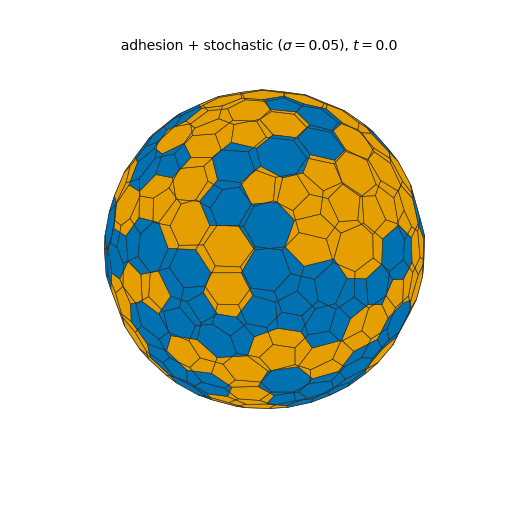

In [10]:
from PIL import Image as PILImage

GIF_FRAMES = 80


def render(draw_frame, t, figsize, projection):
    fig = plt.figure(figsize=figsize)
    try:
        ax = fig.add_subplot(111, projection=projection)
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore")
            draw_frame(ax, t)
        fig.canvas.draw()
        return PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())).convert("RGB")
    finally:
        plt.close(fig)


def save_gif(draw_frame, times, path, figsize, fps=12, projection=None):
    # tyssue's sheet_view_3d occasionally fails on a frame (a NaN in its tick-font
    # autoscale) and succeeds on the same frame when redrawn, so a failed frame is
    # retried once and only then dropped.
    images, dropped = [], []
    for t in times:
        for attempt in range(2):
            try:
                images.append(render(draw_frame, t, figsize, projection))
                break
            except ValueError:
                if attempt:
                    dropped.append(float(t))
    images[0].save(path, save_all=True, append_images=images[1:],
                   duration=int(1000 / fps), loop=0)
    print(f"wrote {path} ({path.stat().st_size / 1e6:.1f} MB), "
          f"{len(images)} frames, dropped {dropped or 'none'}")
    return path


def archive_times(scenario, run):
    with pd.HDFStore(OUT_DIR / scenario / run / "history.hf5", "r") as store:
        times = np.sort(store.select_column("vert", "time").unique())
    return times[np.unique(np.linspace(0, len(times) - 1, GIF_FRAMES).round().astype(int))]


plt.rcParams["figure.dpi"] = GIF_DPI

def ce_movie_frame(ax, t):
    t, pos, e = ce_frame("s0.05", t)
    draw_ce(ax, pos, e, XLIM, YLIM)
    ax.set_title(rf"directional + stochastic ($\sigma = 0.05$), $t = {t:5.1f}$", fontsize=10)

def sort_movie_frame(ax, t):
    t, sheet = sort_frame("s0.05", t)
    draw_sphere(sheet, ax, rf"adhesion + stochastic ($\sigma = 0.05$), $t = {t:5.1f}$", HALF)

gif_ce = save_gif(ce_movie_frame, archive_times("ce", "s0.05"), FIG_DIR / "ce_s0.05.gif", (5.2, 5.2))
gif_sort = save_gif(sort_movie_frame, archive_times("sort", "s0.05"), FIG_DIR / "sort_s0.05.gif",
                    (4.6, 4.6), projection="3d")
plt.rcParams["figure.dpi"] = 110
display(Image(filename=str(gif_ce)))
display(Image(filename=str(gif_sort)))

## Summary

- **The two shares compose exactly.** In every recorded frame of every run, `line_tension` equals the deterministic share plus the stochastic share to within \times10^{-15}$. The stochastic share's spread matches $\sigma$, as an exact OU process at stationarity should.
- **Noise helps both mechanisms, and does neither on its own.** Convergent extension rises from CE = 1.96 (no noise) to 2.25 at $\sigma = 0.1$. Sorting rises from  = 0.55$ to 0.79. The noise-only controls stay at CE $\approx 1$ and  \approx 0.49$.
- **Convergent extension changes character.** Without noise the tissue extends mostly by stretching its cells (aspect ratio 2.2, 30 T1s). With noise the cells stay rounder ($\approx 1.55$) and the tissue extends further by rearranging ($\approx 700$ T1s). The noise unjams the tissue, and the directional tension biases which rearrangements win.
- **Sorting stops being trapped.** Without noise the heterotypic interface shrinks quickly and then stalls. Noise keeps junctions remodelling, so like cells keep gathering.
- With $\sigma \geq 0.05$, 10–25 % of junctions carry negative tension at any moment, because the OU share is centred on 0. Every final mesh passes `Sheet.validate()`.